# 📈 Finding the Line: An Introduction to Linear Models

<div class="alert alert-info">

Welcome! This activity is part of an introduction to computational notebooks for K–12 educators.

In this notebook, we will explore how a **linear model** can help us describe a relationship, make predictions, and ask better questions about data. We will begin with a familiar measurement task, then investigate historical observations of galaxies.

Our goal is to introduce these tools, explore when they are useful, and help you decide how they might fit your classroom.

</div>

<hr style="border: 5px solid #003262;" />

## 🎯 Key Ideas and Learning Goals

A straight line is a simple description of how two quantities vary together. But choosing a line is only the beginning: we also need to interpret it and examine what it misses.

**Our Learning Goals:**

* **Computational/Coding:** Store paired measurements in arrays, modify parameters, select observations, and use reusable functions to generate predictions and plots.
* **Data/Statistical:** Interpret slope and intercept, compare lines using prediction errors, fit a least-squares line, and use residuals to evaluate its limitations.
* **Content/Science:** Explore paper thickness measurements and the relationship between historical estimates of galaxy distance and radial velocity.

We will focus on one explanatory variable and one response variable. We will not derive the fitting formulas or introduce significance tests or multiple regression.

### 🧭 Before You Begin

This notebook assumes familiarity with coordinates and straight-line equations, but little programming experience. Its mathematics is most suitable for secondary classrooms; teachers can adapt the introductory activity for younger learners.

* Run code cells from top to bottom. After changing a value, rerun that cell and any later cells that depend on it.
* Look for comments marked **TRY IT** to find places to modify the analysis.
* Edit the text cells to record predictions and explanations. Save your notebook to keep your work.
* The displayed results are from a completed example run. They do not update until you rerun the code.
* This notebook uses `numpy` and `matplotlib`. All datasets are included below, so no data download or additional script is required.



<hr style="border: 5px solid #003262;" />

# 📏 A Stack of Evidence: Modeling Paper Thickness

Imagine measuring the thickness of stacks containing different numbers of sheets of the same paper.

**Our question:** Can a straight line help us estimate a stack’s thickness from its number of sheets?

The values below are **simulated measurements created for this activity**, not measurements collected in a real experiment. We assume the same kind of paper throughout and do not include a cover or measuring fixture. In a classroom, you could replace these values with repeated measurements and record the measuring instrument’s precision.

## 🔎 Part I: Loading and Looking at the Data

Each pair contains a number of sheets and a thickness in millimeters. Corresponding positions in the two arrays describe the same stack.

Remember: good documentation explains the **why** in text and the **how** in `# code comments`.

<div class="alert alert-success">

**💭 Make a prediction before running the code…**

* If we double the number of sheets, what do you expect to happen to the thickness?

  <br>

* Would you expect every measurement to fall exactly on a straight line? Why?

  <br>

</div>

The first cell imports two libraries: `numpy` supports calculations with lists of numbers, and `matplotlib` creates plots. An **array** is a collection of values that we can calculate with together.

In [4]:
import numpy as np
import matplotlib.pyplot as plt


<a id="set-paper-data"></a>

Sheets | Thickness (mm)
    10 | 1.1
    20 | 1.9
    30 | 3.2
    40 | 3.9
    50 | 5.1
    60 | 5.8
    70 | 7.2
    80 | 8.0


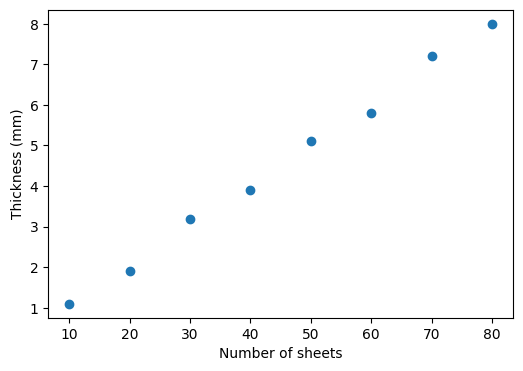

In [16]:
# TRY IT: Replace the paired values with your own measurements.
# Keep each sheet count aligned with its measured thickness.
paper_x = np.array([10, 20, 30, 40, 50, 60, 70, 80], dtype=float)
paper_y = np.array([1.1, 1.9, 3.2, 3.9, 5.1, 5.8, 7.2, 8.0])
print("Sheets | Thickness (mm)")
for x, y in zip(paper_x, paper_y):
    print(f"{x:6.0f} | {y:.1f}")
plt.figure(figsize=(6, 4))
plt.scatter(paper_x, paper_y)
plt.xlabel("Number of sheets")
plt.ylabel("Thickness (mm)")
plt.show()

<div class="alert alert-success">

**💭 Considering the table and scatterplot above…**

* What do you notice and wonder?

  <br>

* What does each point represent? What are the units of each axis?

  <br>

* Does the pattern suggest that a straight line might be useful? What would make you hesitate?

  <br>

</div>

## 📈 Part II: Choosing a Line

We will describe a model’s predictions as

$$\hat{y} = ax + b.$$

* $x$ is the input: the number of sheets.
* $y$ is an observed thickness; $\hat{y}$ is a predicted thickness.
* $a$ is the **slope**, measured here in millimeters per sheet.
* $b$ is the **intercept**, measured in millimeters: the prediction at zero sheets.

For example, if $a=0.10$ and $b=0.20$, the predicted thickness of 30 sheets is $0.10(30)+0.20=3.20$ mm. Adding 10 sheets increases the prediction by 1.00 mm.

Changing the slope changes how quickly the prediction rises or falls. Changing the intercept shifts the line up or down. Because observations need not match predictions exactly, the model is a description of a relationship rather than an equation every measured point must satisfy.

### 🧰 A Few Reusable Tools

Run the next cell once. It defines three functions that we will reuse in both investigations:

* `fit_line` chooses the slope and intercept by least squares.
* `report` summarizes a model and its errors.
* `plot_model` shows observations, a model, and residuals.

You do not need to understand every line yet. A function packages steps we want to repeat, allowing the investigation to focus on questions and choices. Below, `*` means multiplication and `**2` means squaring.

In [6]:
# Reuse the same analysis tools with different datasets.
# Inputs must be finite, paired one-dimensional arrays with varying x values.
import numpy as np
import matplotlib.pyplot as plt

def fit_line(x, y, through_origin=False):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or len(x) < 3 or len(x) != len(y) or not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)) or np.ptp(x) == 0:
        raise ValueError("Use at least three finite paired observations with varying x values.")
    if through_origin:
        a, b = float(x @ y / (x @ x)), 0.0
    else:
        a, b = np.polyfit(x, y, 1)
    residual = y - (a*x + b)
    return float(a), float(b), residual

def report(x, y, a, b):
    residual = y - (a*x + b)
    print(f"y_hat = {a:.3f} x + ({b:.3f})")
    print(f"SSE = {np.sum(residual**2):.3f}")

def plot_model(x, y, a, b, xlabel, ylabel):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    grid = np.linspace(0, max(x)*1.08, 100)
    axes[0].scatter(x, y, color="#187a87", label="Observed")
    axes[0].plot(grid, a*grid+b, color="#b24d26", label="Model")
    axes[0].vlines(x, a*x+b, y, color="gray", alpha=.55)
    axes[0].set(xlabel=xlabel, ylabel=ylabel)
    axes[0].legend()
    residual = y-(a*x+b)
    axes[1].scatter(x, residual, color="#187a87")
    axes[1].axhline(0, color="gray")
    axes[1].set(xlabel=xlabel, ylabel="Residual (observed - predicted)")
    fig.tight_layout()
    plt.show()

<a id="set-paper-line"></a>

Start by choosing your own line. Try slopes of `0.08`, `0.10`, and `0.12`, keeping the intercept fixed. Then change the intercept while keeping the slope fixed.

The left plot displays observations and your model. The vertical segments connect each observed value to its prediction. The right plot displays these differences as **residuals**, introduced below. You can first focus on the left plot.

y_hat = 0.080 x + (0.500)
SSE = 3.240


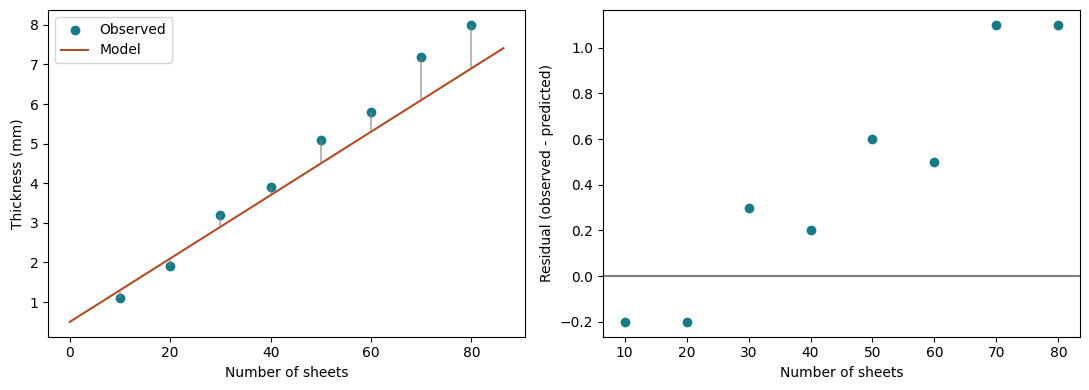

In [7]:
# TRY IT: Change one parameter at a time, then rerun this cell.
my_a = 0.08
my_b = 0.5
report(paper_x, paper_y, my_a, my_b)
plot_model(paper_x, paper_y, my_a, my_b, "Number of sheets", "Thickness (mm)")

<div class="alert alert-success">

**💭 Choosing and explaining your line…**

* What changed when you changed the slope? What changed when you changed the intercept?

  <br>

* Which values would you choose, and why?

  <br>

* Would two people necessarily choose the same line by eye? How could we compare their choices?

  <br>

</div>

## ⚖️ Part III: Comparing Predictions with Observations

A **residual** is the difference between an observation and its model prediction:

$$\text{residual}=y-\hat{y}.$$

A positive residual means the model predicted too low; a negative residual means it predicted too high.

For an observed thickness of 3.2 mm, a prediction of 2.9 mm gives a residual of +0.3 mm. A prediction of 3.5 mm gives a residual of −0.3 mm. These have the same size, but opposite directions.

If we simply add residuals, positive and negative differences can cancel. Instead, we will compare lines using the **sum of squared errors (SSE)**:

$$\mathrm{SSE}=\sum_i(y_i-\hat{y}_i)^2.$$

Squaring makes every contribution nonnegative and gives larger errors more weight. SSE is one useful criterion, rather than the only possible criterion. For the **same observations**, a smaller SSE means a closer fit by this criterion.

<div class="alert alert-success">

**💭 Before comparing these three candidates…**

* Which candidate below do you expect to have the smallest SSE? Explain your prediction.

  <br>

* Can the line with the smallest SSE among three candidates be assumed best among all possible lines?

  <br>

</div>

In [8]:
# Compare three candidate lines using exactly the same observations.
for label, a, b in [("A", 0.08, 0.50), ("B", 0.10, 0.00), ("C", 0.12, -0.50)]:
    error = paper_y - (a*paper_x+b)
    print(f"{label}: a={a:.2f}, b={b:+.2f}; SSE={np.sum(error**2):.3f} mm^2")

A: a=0.08, b=+0.50; SSE=3.240 mm^2
B: a=0.10, b=+0.00; SSE=0.160 mm^2
C: a=0.12, b=-0.50; SSE=3.000 mm^2


<div class="alert alert-success">

**💭 Considering the comparison…**

* Which line has the smallest SSE? Was this what you expected?

  <br>

* What information does SSE provide that looking at the plot alone did not?

  <br>

</div>

### Letting the Computer Find a Least-Squares Line

Rather than checking only three candidates, **least-squares fitting** chooses parameters that minimize SSE over all straight lines of the chosen form. We will use the calculation without deriving its formula.

Once a line has been fitted, we still need to examine whether it is a useful description.

Least-squares fit:
y_hat = 0.100 x + (0.036)
SSE = 0.155


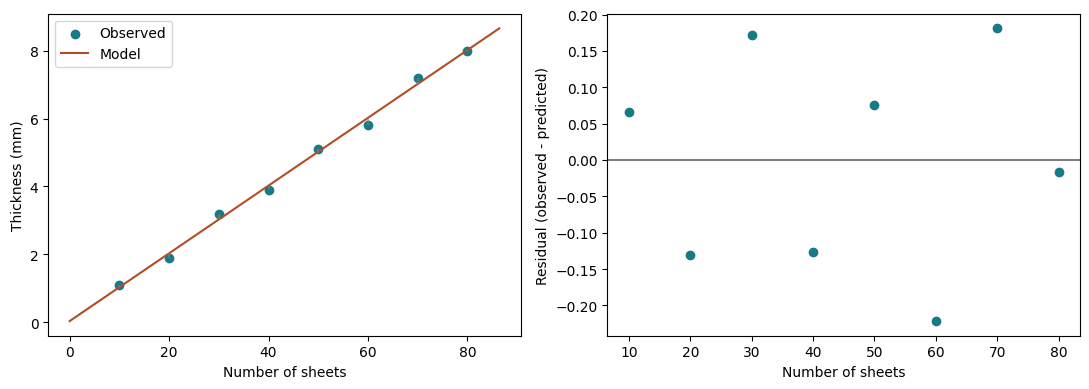

At 45 sheets: 4.53 mm
At 800 sheets: 79.85 mm (extrapolation, not validated)


In [9]:
# Fit a line, inspect its residuals, and compare two prediction locations.
paper_a, paper_b, paper_r = fit_line(paper_x, paper_y)
print("Least-squares fit:")
report(paper_x, paper_y, paper_a, paper_b)
plot_model(paper_x, paper_y, paper_a, paper_b, "Number of sheets", "Thickness (mm)")
print(f"At 45 sheets: {paper_a*45+paper_b:.2f} mm")
print(f"At 800 sheets: {paper_a*800+paper_b:.2f} mm (extrapolation, not validated)")

### 🔍 Reading the Residual Plot

The residual plot keeps the original horizontal axis, but replaces thickness with observed minus predicted thickness. A point on the zero line was predicted exactly.

Look for systematic patterns, such as a curve, clusters, or a spread that increases with the input. Such patterns can suggest a missing feature of the relationship. A pattern-free plot with only eight observations does not prove that the model is correct.

Also read the numerical scale: automatic axis scaling can make small residuals look large.

<div class="alert alert-success">

**💭 Considering the fitted model…**

* Interpret the slope in a sentence that includes units.

  <br>

* How does your chosen line compare with the fitted line?

  <br>

* A prediction for 45 sheets is inside the observed range; one for 800 sheets is far outside it. Why should we treat them differently?

  <br>

* What can you conclude from the residuals? What can you not conclude?

  <br>

</div>

### From a General Line to Direct Proportionality

A general linear model is ŷ=ax+b. When the question calls for a line through the origin, we set b=0 from the start and obtain ŷ=ax. Direct proportionality is a special case of a linear model; it does not mean a fitted intercept later disappears.

In the Hubble investigation below, we will use only a line through the origin.

### 🔄 Let’s Try It Again

[Return to the parameter cell](#set-paper-line) to test another line, or [return to the measurements](#set-paper-data) to explore a different set of paired values. Keep a copy of the original measurements so that you can compare results.

**Record your thinking:** “I first expected… After changing… I observed… My evidence is… I am still unsure about…”

**Summary:** You have used a line to make predictions, interpreted its parameters, and compared predictions with observations. Now we will apply the same method to a different scientific setting.

<hr style="border: 5px solid #003262;" />

# 🌌 Looking Farther: Investigating Historical Galaxy Observations

A simple model can reveal a broad pattern even when individual observations vary considerably.

**Our questions:** Can a line through the origin summarize the relationship between distance and radial velocity? What does it miss?

We will investigate 24 historical observations associated with Hubble’s 1929 paper. Our focus remains the modeling process.

## 🔭 Part I: Understanding and Loading the Data

* **Distance** is measured in megaparsecs (Mpc): one Mpc is one million parsecs.
* **Radial velocity** is measured in kilometers per second (km/s). Positive values indicate motion away along the line of sight; negative values indicate motion toward us.
* Each row corresponds to one named astronomical object. Names identify observations; they are not categories in our model.

The distance estimates and velocities are historical measurements, not simulated points placed around a line. Distance estimates involve astronomical measurement methods; radial velocities are inferred from spectral information. We use the prepared values without reconstructing those measurements.

**Historical context matters:** These distances use an old calibration. A slope fitted here is **not a measurement of today’s Hubble constant**. Our calculation also does not reproduce the original paper’s full analysis, including corrections for solar motion. The exact CSV transcription and original paper are linked in Credits.

<div class="alert alert-success">

**💭 Let’s think like scientists…**

* What pattern do you expect between distance and radial velocity?

  <br>

* Would a negative velocity automatically mean a recording error? What context would you need?

  <br>

* What columns and units should we check before fitting a model?

  <br>

</div>

24 observations; distance: 0.032–2.0 Mpc


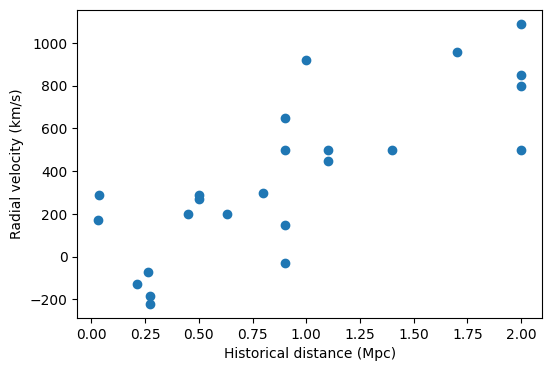

In [10]:
# Historical observations are embedded for reproducibility.
# distance is in Mpc; velocity is in km/s. See Credits for provenance.
names = ["S.Mag", "L.Mag", "NGC.6822", "NGC.598", "NGC.221", "NGC.224", "NGC.5457", "NGC.4736", "NGC.5194", "NGC.4449", "NGC.4214", "NGC.3031", "NGC.3627", "NGC.4826", "NGC.5236", "NGC.1068", "NGC.5055", "NGC.7331", "NGC.4258", "NGC.4151", "NGC.4382", "NGC.4472", "NGC.4486", "NGC.4649"]
distance = np.array([.032,.034,.214,.263,.275,.275,.45,.5,.5,.63,.8,.9,.9,.9,.9,1,1.1,1.1,1.4,1.7,2,2,2,2])
velocity = np.array([170,290,-130,-70,-185,-220,200,290,270,200,300,-30,650,150,500,920,450,500,500,960,500,850,800,1090], dtype=float)
print(f"{len(distance)} observations; distance: {distance.min():.3f}–{distance.max():.1f} Mpc")
plt.figure(figsize=(6, 4))
plt.scatter(distance, velocity)
plt.xlabel("Historical distance (Mpc)")
plt.ylabel("Radial velocity (km/s)")
plt.show()

<div class="alert alert-success">

**💭 Considering the scatterplot…**

* What do you notice and wonder?

  <br>

* Is there an overall trend? How much variation do you see around it?

  <br>

* What would you want a model to summarize, and what might it conceal?

  <br>

</div>

## 📈 Part II: Fitting and Checking a Proportional Model

The idealized Hubble relation is:

$$v=Hd.$$

Here d is distance, v is recession velocity, and H is the proportionality constant. This is the special case of ŷ=ax+b in which b is fixed at zero from the start: the model line passes through the origin.

For predictions, we write:

$$\hat{v}=Hd.$$

We estimate only H, not an intercept. Its units are $(\mathrm{km/s})/\mathrm{Mpc}$. In the model, doubling the distance doubles the predicted velocity. H is a proportionality constant, not an individual galaxy's velocity.

Actual historical observations include other motions and measurement limitations, so points need not lie exactly on the line. The coefficient fitted here is not a modern measurement of the Hubble constant.

Before running the code, predict what patterns you might see in the residuals.

y_hat = 423.937 x + (0.000)
SSE = 1206402.638


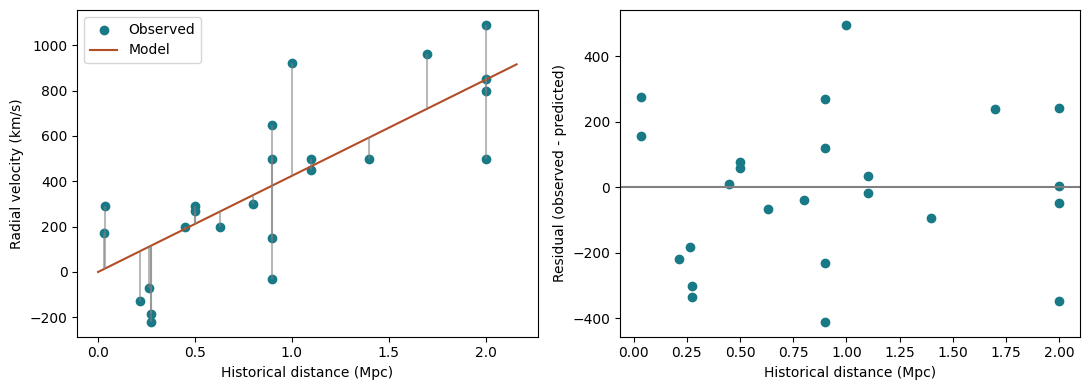

Largest absolute residuals:
NGC.1068: observed=920, predicted=423.9, residual=+496.1 km/s
NGC.3031: observed=-30, predicted=381.5, residual=-411.5 km/s
NGC.4382: observed=500, predicted=847.9, residual=-347.9 km/s


In [11]:
# Fix the intercept at zero and estimate only the proportionality constant H.
# Use the same fitting and plotting functions as in the paper task.
# Identify large residuals for investigation, not automatic removal.
h_a, h_b, h_r = fit_line(distance, velocity, through_origin=True)
report(distance, velocity, h_a, h_b)
plot_model(distance, velocity, h_a, h_b, "Historical distance (Mpc)", "Radial velocity (km/s)")
print("Largest absolute residuals:")
for i in np.argsort(np.abs(h_r))[-3:][::-1]:
    print(f"{names[i]}: observed={velocity[i]:.0f}, predicted={h_a*distance[i]+h_b:.1f}, residual={h_r[i]:+.1f} km/s")

<div class="alert alert-success">

**💭 Interpreting the model and residuals…**

* How can a broad increasing trend coexist with large individual residuals?

  <br>

* Which named observations are predicted too high or too low?

  <br>

* Could the residual plot alone tell us why a particular object differs?

  <br>

* Why can we not compare the numerical SSE of paper thickness with the SSE of galaxy velocity to judge which model is better?

  <br>

</div>

## 🧪 Part III: Try Your Own Proportionality Constant

Keep all 24 observations and the zero intercept fixed. Change only H; try 300, 400, and 500.

**Predict first:** Which value will bring the line closer to these data, and why?

The code compares your line's SSE with the least-squares fit on exactly the same observations. A smaller SSE means a closer fit by this criterion, not proof that the scientific explanation is correct.

A large residual is a reason to investigate, not sufficient justification for deleting an observation.

<a id="set-hubble-model"></a>

Your proportional model:
y_hat = 400.000 x + (0.000)
SSE = 1223316.200


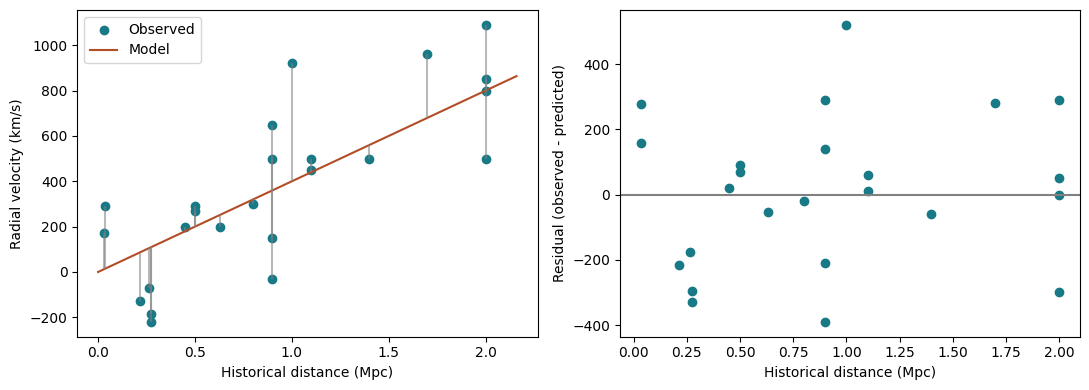

Your SSE: 1223316.20 (km/s)^2
Least-squares H: 423.94; SSE: 1206402.64 (km/s)^2
Fitted-model prediction at 1.5 Mpc: 635.9 km/s


In [19]:
# TRY IT: Change only my_H; the intercept stays at zero.
my_H = 400
print("Your proportional model:")
report(distance, velocity, my_H, 0)
plot_model(distance, velocity, my_H, 0, "Historical distance (Mpc)", "Radial velocity (km/s)")
print(f"Your SSE: {np.sum((velocity-my_H*distance)**2):.2f} (km/s)^2")
print(f"Least-squares H: {h_a:.2f}; SSE: {np.sum(h_r**2):.2f} (km/s)^2")
print(f"Fitted-model prediction at 1.5 Mpc: {h_a*1.5:.1f} km/s")

<div class="alert alert-success">

**💭 Document your investigation…**

* Which H did you choose, and what did you predict?
* With the data and intercept fixed, how did H affect the line, residuals, and SSE?
* How does your SSE compare with the fitted line's SSE?
* Does minimizing SSE mean every object is predicted accurately?
* What conclusions remain unsupported by these observations?

</div>

[Return to the proportionality constant](#set-hubble-model) to try another value.

Keep your prediction and evidence. A smaller SSE supports a closer fit to these observations, but does not guarantee performance on new observations.

<div class="alert alert-success">

**💭 Tell the story of your analysis…**

* Complete: “I investigated… using… observations. I chose… because… The slope means… My evidence is… When I changed… the result… This does not establish… Next, I would…”

  <br>

* Which plot or number would you show someone to support your interpretation?

  <br>

* What new question did the analysis raise?

  <br>

</div>

<hr style="border: 1px solid #fdb515;" />

## 🌀 Optional Extension: An Increasing Pattern Is Not Always Linear

The following **simulated** relationship increases with its input but has curvature. Predict the residual pattern before fitting a straight line.

This extension checks the limitations of a linear model. It does not require learning another fitting method.

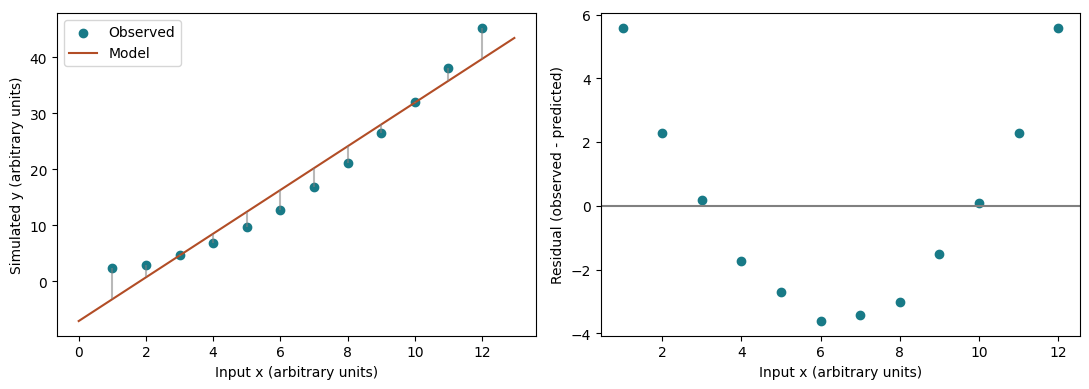

Look for a systematic U-shaped residual pattern rather than a random cloud.


In [13]:
# A separate simulated dataset, not modified historical observations.
curve_x = np.arange(1, 13, dtype=float)
curve_y = 2 + 0.3*curve_x**2 + np.array([.1,-.2,.1,0,.2,-.1,.1,-.1,.2,0,-.2,.1])
curve_a, curve_b, curve_r = fit_line(curve_x, curve_y)
plot_model(curve_x, curve_y, curve_a, curve_b, "Input x (arbitrary units)", "Simulated y (arbitrary units)")
print("Look for a systematic U-shaped residual pattern rather than a random cloud.")

<div class="alert alert-success">

**💭 Considering this example…**

* What pattern appears in the residuals?

  <br>

* Why might an increasing fitted line still be an inadequate description?

  <br>

* What would you investigate next: another model form, another variable, or a narrower range? Explain.

  <br>

</div>

<hr style="border: 1px solid #fdb515;" />

## 🏫 In the Classroom

The transferable process is **observe → propose a model → fit → check → explain**. The application can change while that process remains useful.

**Where else might we use it?**

* **Physics:** Investigate load and extension for the same spring within an appropriate range.
* **School measurement:** Collect repeated measurements of stacks of the same paper, recording instrument precision.
* **Everyday quantities:** Investigate price and quantity where fixed fees, discounts, or changing unit prices may affect the model.

Changing contexts requires more than replacing a data link. Update variable definitions, units, measurement assumptions, parameter meanings, and prediction questions. Check whether a line is appropriate and whether a zero intercept has a meaningful justification.

### Why Use a Notebook?

Paper-and-pencil work can make a single prediction or residual tangible. A spreadsheet can also fit a line and generate plots. A notebook keeps editable calculations, figures, choices, and explanations together in a repeatable narrative.

That benefit comes with learning to read some code and manage execution order. The purpose is to decide when these affordances serve your classroom, rather than assume a notebook is always the best tool.

<div class="alert alert-success">

**💭 Reflecting as a teacher…**

* Which step helped you understand something that a formula alone did not?

  <br>

* Which calculations would you delegate to a computer? Which judgments still require explanation?

  <br>

* What could your students change meaningfully? What would you ask them to document?

  <br>

* How would you adapt the level of guidance for your students?

  <br>

</div>

### Supporting Student Thinking

* If a learner confuses an observation with a prediction, ask them to point to a measured point and the point on the line at the same input.
* If a learner treats a negative residual as a mistake, ask whether the model overpredicted or underpredicted.
* If a learner chooses a model only because it has lower error, ask about the measurement definition and evaluation range.
* If a learner removes inconvenient points, ask for independent evidence that a measurement is invalid and retain a full-data comparison.
* If a learner runs cells without investigating, ask for a prediction before the next run and one piece of evidence afterward.

For a formative check, ask each learner to explain a slope with units, calculate one residual, compare one modeling choice fairly, and state a conclusion with a limitation.

### Troubleshooting

* **`NameError`:** Run the earlier cells that define the variable or function.
* **Old or inconsistent results:** Restart the kernel and run all cells in order.
* **`ModuleNotFoundError`:** Use a Python environment with `numpy` and `matplotlib` installed.
* **An unexpected result:** Check units and inputs, then consider whether the model is appropriate. A large residual does not automatically indicate a coding error.

<hr style="border: 1px solid #fdb515;" />

## 📚 Connections to K–12 Standards

These connections identify practices supported by this activity, not a claim that one notebook covers every requirement of a standard.

### Common Core State Standards for Mathematics

* **[HSS-ID.B.6a](https://www.thecorestandards.org/Math/Content/HSS/ID/B/6/a/):** Fit functions and use them to address contextual problems. Here, learners fit a line and interpret predictions.
* **[HSS-ID.B.6b](https://www.thecorestandards.org/Math/Content/HSS/ID/B/6/b/):** Informally assess fit using residual plots. Both investigations require examining deviations from the model.
* **[HSS-ID.B.6c](https://www.thecorestandards.org/Math/Content/HSS/ID/B/6/c/):** Fit a line when a scatterplot suggests a linear association.
* **[HSS-ID.C.7](https://www.thecorestandards.org/Math/Content/HSS/ID/C/7/):** Interpret slope and intercept in the context of the data.

### Next Generation Science Standards

* **Practice 4 — Analyzing and Interpreting Data:** Examine patterns, compare results, and consider measurement and sample limitations.
* **Practice 5 — Using Mathematics and Computational Thinking:** Represent relationships and use computational calculations to compare models.

See [NGSS Appendix F](https://www.nextgenscience.org/sites/default/files/Appendix%20F%20%20Science%20and%20Engineering%20Practices%20in%20the%20NGSS%20-%20FINAL%20060513.pdf) for the practice descriptions. This notebook does not independently address a complete astronomy performance expectation.

<hr style="border: 1px solid #fdb515;" />

## 🙌 Credits

**Data and scientific sources:**

* The paper measurements and curved example are simulated datasets created for this activity.
* Hubble, E. (1929). *A relation between distance and radial velocity among extra-galactic nebulae.* Proceedings of the National Academy of Sciences, 15, 168–173. [Original article](https://doi.org/10.1073/pnas.15.3.168); [scan of the paper](https://www.astro.puc.cl/~rparra/tools/PAPERS/hubble_1929.pdf).
* The 24 embedded historical observations were taken from the [CSV transcription in Astro Data Science](https://raw.githubusercontent.com/behrouzz/astrodatascience/main/data/hubble1929.csv). All 24 CSV rows were inspected. A row-by-row collation against the original scanned table has not yet been completed.
* Curriculum references are linked in the standards section.

All data required to run the notebook are embedded in its code cells. No separate data file or webpage is needed.

[NASA explanation of the proportional Hubble relation](https://imagine.gsfc.nasa.gov/features/yba/M31_velocity/hubble_law/hubble_meaning.html).